# 9. Geofencing và Realtime: độ trễ, tỷ lệ phát hiện, tính nhất quán

Hai phép đo của đề cương mục 4.5 không phải thuật toán riêng nhưng cần số liệu cho chương 4:

* **Geofencing** (`BE/apps/algorithms/geofence.py`): người học đi thẳng ngang qua các POI thật (đi bộ 1,4 m/s, xe đạp
  4,5 m/s, xe máy 8 m/s), GPS mỗi giây lệch ~8 m. App áp dụng đúng chính sách kiểm tra trong `location_service.dart`:
  chỉ nhận vị trí mới sau khi đi được `distanceFilter` mét, và chỉ gọi `/geofence/check/` nếu lần trước đã cách
  `min_interval` giây. Máy chủ kiểm tra bằng chỉ mục lưới + Haversine, d ≤ bán kính POI.
  So sánh chính sách cũ (100 m / 2 phút, phương pháp cơ sở) với các chính sách dày hơn.
* **Realtime** (`BE/apps/algorithms/realtime.py`): đo qua ứng dụng ASGI thật (xác thực JWT, consumer, database,
  channel layer). Chat nhóm 6 người, tin nhắn riêng tới socket sự kiện của cả hai người, ping–pong, chống dồn tin.

Nguồn số liệu: nếu có `AI/report/experiments/production.json` (lấy bằng `run-experiments.bat`, chạy trên server
lingoprism.id.vn với Redis) thì dùng số của production; số chạy trên máy này luôn được đo lại để so sánh.

> **Cách chạy:** chọn kernel **LingoPrism (BE venv)** rồi *Run All* (PostgreSQL phải đang chạy). Biểu đồ lưu ở
> `AI/notebooks/figures/09_*.png`, bảng Markdown để chép vào báo cáo lưu ở `AI/report/experiments/bang_ket_qua.md`.

In [1]:
# Khởi tạo: nạp Django của BE/ (database + mã thật của server) và matplotlib
import pathlib, sys
_here = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "AI/notebooks/lingoprism_setup.py").exists())
sys.path.insert(0, str(_here / "AI/notebooks"))
from lingoprism_setup import ROOT, init, save, table
init()

import json, math, random
import numpy as np
import matplotlib.pyplot as plt

Django OK – config.settings.dev | hình lưu ở D:\kicuoi\doantotnghiep\SnapLingua-main\AI\notebooks\figures


In [2]:
PASSES = 120  # số lượt đi qua cho mỗi ô (chính sách × cách di chuyển)

from apps.algorithms import experiments, geofence as gf

REPORT = ROOT / "AI/report/experiments"
REPORT.mkdir(parents=True, exist_ok=True)
prod_file = REPORT / "production.json"
prod = json.loads(prod_file.read_text(encoding="utf-8"))["runs"] if prod_file.exists() else {}
print("Số liệu production:", ", ".join(f"{k} ({v['created_at'][:16]})" for k, v in prod.items()) if prod else "chưa có – chạy run-experiments.bat")

# Jupyter already runs an event loop: the realtime measurement (async inside) gets a thread of its own
from concurrent.futures import ThreadPoolExecutor
with ThreadPoolExecutor(1) as pool:
    rt_run = pool.submit(experiments.realtime).result()
local = {"geofence": experiments.geofence(PASSES).results, "realtime": rt_run.results}
geo = prod["geofence"]["results"] if "geofence" in prod else local["geofence"]
rt_prod = prod.get("realtime", {}).get("results")
rt_local = local["realtime"]
print(f"Geofence: {geo['pois']} POI, {geo['passes_per_cell']} lượt/ô, nguồn = {'production' if 'geofence' in prod else 'máy này'}")

Số liệu production: benchmark (2026-11-04 12:40), vision (2026-10-22 15:57), srs (2026-11-04 12:36), ga (2026-11-04 12:37), vip (2026-11-04 12:37), distractor (2026-11-04 12:39), proximity (2026-11-04 12:40), geofence (2026-11-04 12:37), realtime (2026-11-04 12:37)


Geofence: 30 POI, 120 lượt/ô, nguồn = production


## 9.1 Minh hoạ: một lần đi xe đạp ngang qua POI

Chấm xám: vị trí GPS mỗi giây (có nhiễu). Dấu ×: lúc app gọi máy chủ kiểm tra. Chính sách cũ chỉ kiểm tra khi đã đi
100 m **và** đã qua 2 phút, nên có thể đi xuyên qua vùng mà không lần kiểm tra nào rơi vào bên trong.

WindowsPath('D:/kicuoi/doantotnghiep/SnapLingua-main/AI/notebooks/figures/09_geofence_minh_hoa.png')

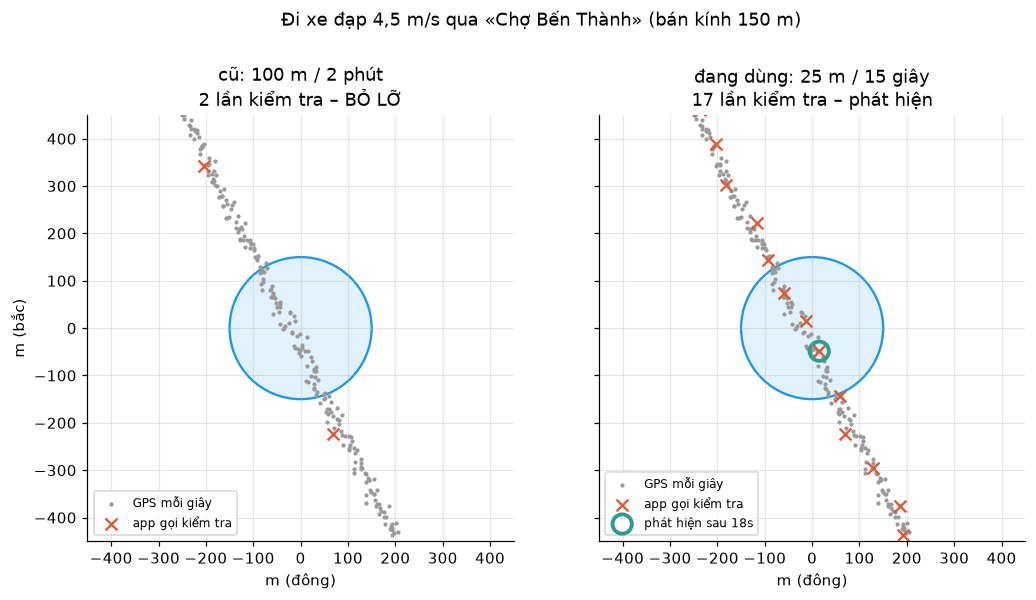

In [3]:
from apps.gis.models import Poi
from apps.algorithms.proximity import GridIndex

pois = list(Poi.objects.filter(is_active=True).values_list("id", "lat", "lng", "radius_m"))
index = GridIndex([(p[0], p[1], p[2]) for p in pois])
radius_of = {p[0]: p[3] for p in pois}
poi = min(pois, key=lambda p: abs(p[3] - 150))
rng = random.Random(7)
fixes, entry, exit_ = gf._pass(rng, poi, gf.SPEEDS["xe đạp"], inside=True)

def to_m(lat, lng):
    return ((lng - poi[2]) * gf.M_PER_DEG * math.cos(math.radians(poi[1])), (lat - poi[1]) * gf.M_PER_DEG)

xy = np.array([to_m(*f) for f in fixes])
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharex=True, sharey=True)
for ax, name in zip(axes, (gf.BASELINE, gf.CURRENT)):
    dist_f, interval = gf.POLICIES[name]
    times, found = gf._run_policy(fixes, poi[0], radius_of, index, dist_f, interval, random.Random(1))
    ax.add_patch(plt.Circle((0, 0), poi[3], color="#1899f0", alpha=0.12))
    ax.add_patch(plt.Circle((0, 0), poi[3], fill=False, color="#1899f0", lw=1.5))
    ax.scatter(xy[:, 0], xy[:, 1], s=3, color="#999", label="GPS mỗi giây")
    ax.scatter(xy[times, 0], xy[times, 1], marker="x", s=60, color="#e4572e", label="app gọi kiểm tra")
    if found is not None:
        ax.scatter(*xy[found], s=160, facecolor="none", edgecolor="#2a9d8f", lw=2.5, label=f"phát hiện sau {found - entry}s")
    ax.set_title(f"{name}\n{len(times)} lần kiểm tra – {'phát hiện' if found is not None and found <= exit_ + gf.GRACE_S else 'BỎ LỠ'}")
    ax.set_aspect("equal"); ax.set_xlim(-450, 450); ax.set_ylim(-450, 450); ax.set_xlabel("m (đông)")
    ax.legend(loc="lower left", fontsize=8)
axes[0].set_ylabel("m (bắc)")
fig.suptitle(f"Đi xe đạp 4,5 m/s qua «{Poi.objects.get(id=poi[0]).name}» (bán kính {poi[3]} m)", y=1.05)
save(fig, "09_geofence_minh_hoa")

## 9.2 Tỷ lệ phát hiện và độ trễ kích hoạt theo chính sách

*Phát hiện*: lần đi ngang được nhận ra trước khi ra khỏi vùng + 30 giây. *Trễ*: lúc phát hiện − lúc thật sự vào vùng,
chỉ tính trên các lần được phát hiện (nên trễ của chính sách bỏ lỡ nhiều trông thấp hơn thực tế: so độ trễ ở dòng đi bộ).

chính sách                 di chuyển  phát hiện  trễ TB (s)  trung vị  p95  báo nhầm  gọi/giờ 
-------------------------  ---------  ---------  ----------  --------  ---  --------  --------
cũ: 100 m / 2 phút         đi bộ      93.3%      54.1000     61.0000   125  3.3%      23.6000 
cũ: 100 m / 2 phút         xe đạp     48.9%      34.5000     31.0000   69   0.0%      25.6000 
cũ: 100 m / 2 phút         xe máy     40.0%      23.2000     18.0000   51   0.0%      28.0000 
25 m / 30 giây             đi bộ      100.0%     13.5000     11.5000   38   0.0%      95.0000 
25 m / 30 giây             xe đạp     97.8%      14.8000     14.0000   29   0.0%      106.6000
25 m / 30 giây             xe máy     85.6%      13.1000     13        28   0.0%      110.5000
đang dùng: 25 m / 15 giây  đi bộ      100.0%     5.9000      4.0000    18   0.0%      160.8000
đang dùng: 25 m / 15 giây  xe đạp     100.0%     8.1000      8.0000    16   0.0%      192.6000
đang dùng: 25 m / 15 giây  xe máy     97.8%      7

WindowsPath('D:/kicuoi/doantotnghiep/SnapLingua-main/AI/notebooks/figures/09_geofence_do_tre.png')

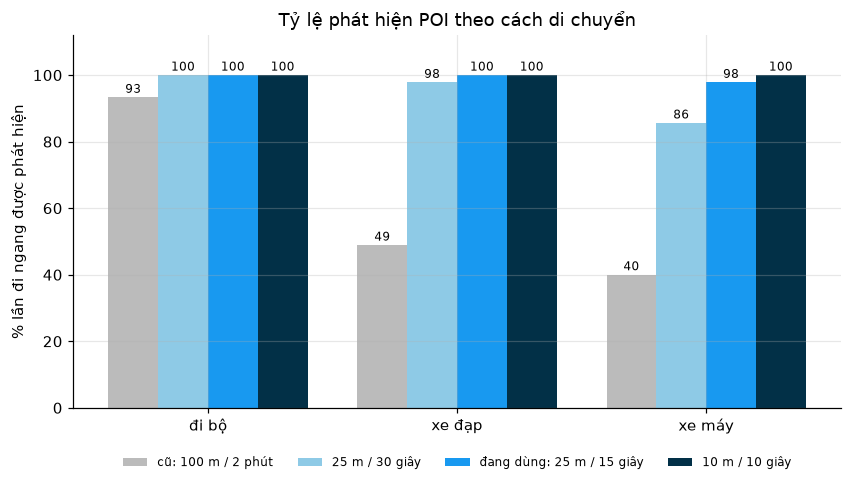

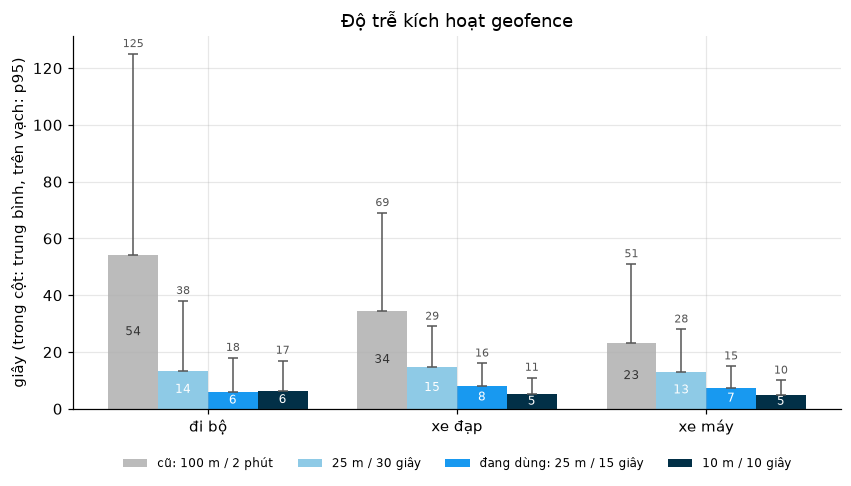

In [4]:
rows = geo["rows"]
table([{"chính sách": r["policy"], "di chuyển": r["mode"], "phát hiện": f"{r['detected_rate']:.1%}",
        "trễ TB (s)": r["delay_mean_s"], "trung vị": r["delay_p50_s"], "p95": r["delay_p95_s"],
        "báo nhầm": f"{r['false_rate']:.1%}", "gọi/giờ": r["checks_per_hour"]} for r in rows])
print(f"\nMáy chủ kiểm tra một lần: TB {geo['server_check']['mean_ms']} ms, p95 {geo['server_check']['p95_ms']} ms")

policies = list(gf.POLICIES) if set(gf.POLICIES) == {r["policy"] for r in rows} else list(dict.fromkeys(r["policy"] for r in rows))
modes = list(gf.SPEEDS)
colors = ["#bbbbbb", "#8ecae6", "#1899f0", "#023047"]
cell = {(r["policy"], r["mode"]): r for r in rows}

fig, ax = plt.subplots(figsize=(9, 4.4))
w = 0.8 / len(policies)
for i, p in enumerate(policies):
    vals = [cell[(p, m)]["detected_rate"] * 100 for m in modes]
    bars = ax.bar(np.arange(len(modes)) + (i - (len(policies) - 1) / 2) * w, vals, w, label=p, color=colors[i % 4])
    ax.bar_label(bars, fmt="%.0f", fontsize=8, padding=1)
ax.set_xticks(range(len(modes)), modes); ax.set_ylabel("% lần đi ngang được phát hiện"); ax.set_ylim(0, 112)
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
ax.set_title("Tỷ lệ phát hiện POI theo cách di chuyển")
save(fig, "09_geofence_phat_hien")

fig, ax = plt.subplots(figsize=(9, 4.4))
for i, p in enumerate(policies):
    mean = [cell[(p, m)]["delay_mean_s"] or 0 for m in modes]
    p95 = [cell[(p, m)]["delay_p95_s"] or 0 for m in modes]
    x = np.arange(len(modes)) + (i - (len(policies) - 1) / 2) * w
    bars = ax.bar(x, mean, w, label=p, color=colors[i % 4])
    ax.errorbar(x, mean, yerr=[np.zeros(len(mean)), np.array(p95) - np.array(mean)], fmt="none", ecolor="#555", capsize=3, lw=1)
    for xi, m_, p_ in zip(x, mean, p95):  # mean inside the bar, p95 above its whisker: no overlap with the whisker
        ax.text(xi, m_ / 2, f"{m_:.0f}", ha="center", va="center", fontsize=8, color="white" if i else "#333")
        ax.text(xi, p_ + 1.5, f"{p_:.0f}", ha="center", va="bottom", fontsize=7, color="#555")
ax.set_xticks(range(len(modes)), modes); ax.set_ylabel("giây (trong cột: trung bình, trên vạch: p95)")
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
ax.set_title("Độ trễ kích hoạt geofence")
save(fig, "09_geofence_do_tre")

## 9.3 Đánh đổi: độ trễ ↔ số lần gọi máy chủ

Kiểm tra dày hơn thì phát hiện sớm hơn nhưng app gọi máy chủ nhiều hơn (tải máy chủ, pin). Chính sách đang dùng là
điểm dày nhất mà vẫn chỉ cần ~3 lần gọi mỗi phút khi đang di chuyển.

WindowsPath('D:/kicuoi/doantotnghiep/SnapLingua-main/AI/notebooks/figures/09_geofence_danh_doi.png')

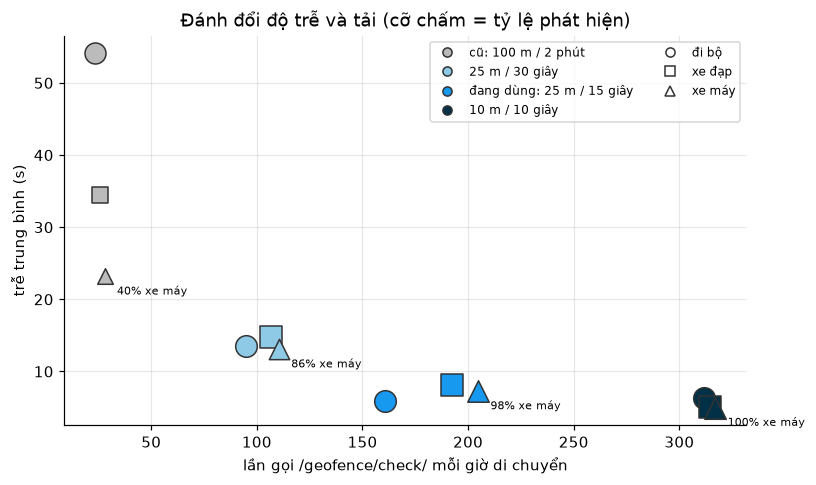

In [5]:
from matplotlib.lines import Line2D
marks = dict(zip(modes, ["o", "s", "^"]))
fig, ax = plt.subplots(figsize=(8, 4.6))
for i, p in enumerate(policies):
    for m in modes:
        r = cell[(p, m)]
        ax.scatter(r["checks_per_hour"], r["delay_mean_s"] or 0, s=40 + 160 * r["detected_rate"], marker=marks[m],
                   color=colors[i % 4], edgecolor="#333", zorder=3)
    ax.annotate(f"{cell[(p, modes[-1])]['detected_rate']:.0%} xe máy", (cell[(p, modes[-1])]["checks_per_hour"], cell[(p, modes[-1])]["delay_mean_s"] or 0),
                textcoords="offset points", xytext=(8, -12), fontsize=7)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=colors[i % 4], markeredgecolor="#333", label=p) for i, p in enumerate(policies)]
          + [Line2D([], [], marker=marks[m], ls="", color="#fff", markeredgecolor="#333", label=m) for m in modes],
          fontsize=8, ncol=2)
ax.set_xlabel("lần gọi /geofence/check/ mỗi giờ di chuyển"); ax.set_ylabel("trễ trung bình (s)")
ax.set_title("Đánh đổi độ trễ và tải (cỡ chấm = tỷ lệ phát hiện)")
save(fig, "09_geofence_danh_doi")

## 9.4 Realtime: độ trễ theo đường đi của tin nhắn

Con số là phần trễ của máy chủ (client WebSocket chạy cùng máy). Trễ mạng thật của điện thoại / trình duyệt cộng thêm
khoảng một vòng ping tới máy chủ.

== máy này (InMemoryChannelLayer)
đường đi                        mẫu  TB (ms)  p50      p95      p99      max    
------------------------------  ---  -------  -------  -------  -------  -------
Ping → pong                     50   0.5000   0.4900   0.7700   0.8300   0.8300 
Nhóm → thành viên khác          240  8.0100   7.3100   11.5200  24.5200  29.8000
Nhóm → người gửi                48   8.6500   7.6900   12.5600  24.7700  24.7700
Tin riêng: gửi + lưu            30   13.0700  12.2700  16.1500  43.5700  43.5700
Tin riêng → người nhận          30   13.4300  12.7100  16.8700  43.7500  43.7500
Tin riêng → máy khác người gửi  30   13.2700  12.5800  16.5100  43.6900  43.6900

== production (RedisChannelLayer)
đường đi                        mẫu  TB (ms)  p50      p95       p99       max     
------------------------------  ---  -------  -------  --------  --------  --------
Ping → pong                     50   0.3000   0.2900   0.3400    0.3500    0.3500  
Nhóm → thành viên khác         

WindowsPath('D:/kicuoi/doantotnghiep/SnapLingua-main/AI/notebooks/figures/09_realtime_do_tre.png')

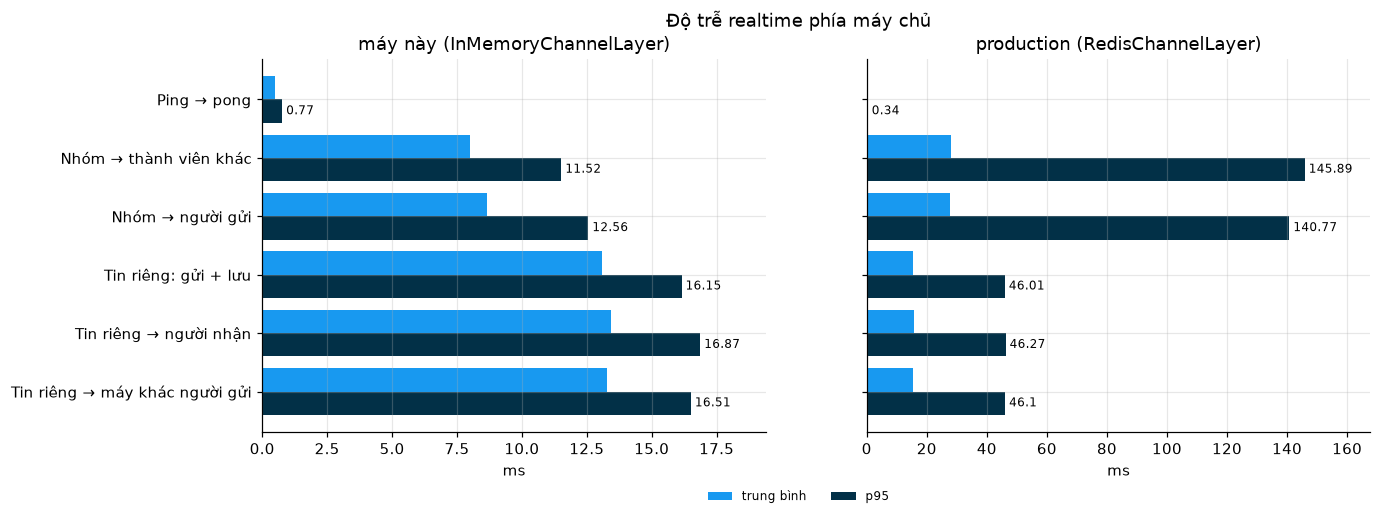

In [6]:
def paths(rt):
    return [("Ping → pong", rt["ping"]),
            ("Nhóm → thành viên khác", rt["group"]["to_other_members"]),
            ("Nhóm → người gửi", rt["group"]["echo_to_sender"]),
            ("Tin riêng: gửi + lưu", rt["dm"]["send_and_store"]),
            ("Tin riêng → người nhận", rt["dm"]["to_recipient"]["latency"]),
            ("Tin riêng → máy khác người gửi", rt["dm"]["to_sender_devices"]["latency"])]

sources = [("máy này (" + rt_local["setup"]["channel_layer"] + ")", rt_local)]
if rt_prod:
    sources.append(("production (" + rt_prod["setup"]["channel_layer"] + ")", rt_prod))
for name, rt in sources:
    print("==", name)
    table([{"đường đi": n, "mẫu": s["n"], "TB (ms)": s["mean_ms"], "p50": s["p50_ms"], "p95": s["p95_ms"],
            "p99": s["p99_ms"], "max": s["max_ms"]} for n, s in paths(rt)])
    print()

fig, axes = plt.subplots(1, len(sources), figsize=(6.5 * len(sources), 4.4), sharey=True, squeeze=False)
for ax, (name, rt) in zip(axes[0], sources):
    ps = paths(rt)
    y = np.arange(len(ps))
    ax.barh(y - 0.2, [s["mean_ms"] for _, s in ps], 0.4, label="trung bình", color="#1899f0")
    ax.barh(y + 0.2, [s["p95_ms"] for _, s in ps], 0.4, label="p95", color="#023047")
    for i, (_, s) in enumerate(ps):
        ax.text(s["p95_ms"], i + 0.2, f" {s['p95_ms']}", va="center", fontsize=8)
    ax.set_yticks(y, [n for n, _ in ps]); ax.set_xlabel("ms"); ax.set_title(name)
    ax.set_xlim(0, max(s["p95_ms"] for _, s in ps) * 1.15)
axes[0][0].invert_yaxis()  # y is shared: invert once, or the two inversions cancel out
fig.legend(*axes[0][0].get_legend_handles_labels(), loc="lower center", ncol=2, fontsize=8, frameon=False,
           bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Độ trễ realtime phía máy chủ")
save(fig, "09_realtime_do_tre")

## 9.5 Realtime: tính nhất quán và chống dồn tin

nguồn                           lượt giao tin nhóm  mất  trùng  cùng thứ tự  gửi lại tạo tin mới  dồn tin nhận/từ chối
------------------------------  ------------------  ---  -----  -----------  -------------------  --------------------
máy này (InMemoryChannelLayer)  288/288             0    0      có           không                8/16                
production (RedisChannelLayer)  288/288             0    0      có           không                8/16                


WindowsPath('D:/kicuoi/doantotnghiep/SnapLingua-main/AI/notebooks/figures/09_realtime_don_tin.png')

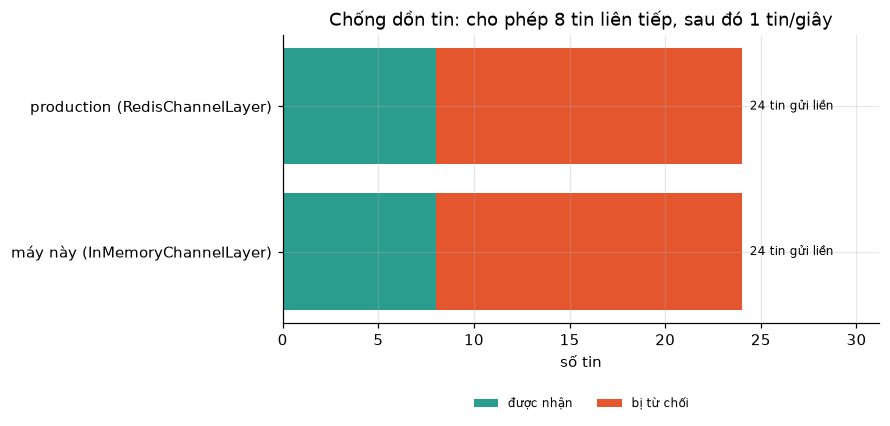

In [7]:
cons = []
for name, rt in sources:
    g, d, f = rt["group"], rt["dm"], rt["flood"]
    cons.append({"nguồn": name, "lượt giao tin nhóm": f"{g['deliveries']}/{g['deliveries_expected']}",
                 "mất": g["missing"] + d["to_recipient"]["missing"], "trùng": g["duplicates"] + d["to_recipient"]["duplicates"],
                 "cùng thứ tự": "có" if g["same_order_everywhere"] and d["to_recipient"]["in_order"] else "không",
                 "gửi lại tạo tin mới": "có" if g["resend_creates_new"] else "không",
                 "dồn tin nhận/từ chối": f"{f['accepted']}/{f['refused']}"})
table(cons)

fig, ax = plt.subplots(figsize=(7, 3.4))
for i, (name, rt) in enumerate(sources):
    f = rt["flood"]
    ax.barh(i, f["accepted"], color="#2a9d8f", label="được nhận" if i == 0 else None)
    ax.barh(i, f["refused"], left=f["accepted"], color="#e4572e", label="bị từ chối" if i == 0 else None)
    ax.text(f["sent"], i, f"  {f['sent']} tin gửi liền", va="center", fontsize=8)
ax.set_xlim(0, max(rt["flood"]["sent"] for _, rt in sources) * 1.3)
ax.set_yticks(range(len(sources)), [n for n, _ in sources]); ax.set_xlabel("số tin")
ax.set_title(f"Chống dồn tin: cho phép {sources[0][1]['flood']['burst_allowed']} tin liên tiếp, sau đó 1 tin/giây")
ax.legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False)
save(fig, "09_realtime_don_tin")

## 9.6 Bảng Markdown cho báo cáo

Ghi vào `AI/report/experiments/bang_ket_qua.md` (chép thẳng vào Word / Google Docs).

In [8]:
def mdt(rows):
    cols = list(rows[0])
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    out += ["| " + " | ".join(str(r[c]) for c in cols) + " |" for r in rows]
    return "\n".join(out)

src = "production (lingoprism.id.vn)" if "geofence" in prod else "máy phát triển"
parts = [f"# Kết quả geofence và realtime\n\nNguồn geofence: {src}, {geo['pois']} POI, {geo['passes_per_cell']} lượt đi qua mỗi ô, "
         f"nhiễu GPS {geo['gps_sigma_m']} m. Máy chủ kiểm tra một lần: TB {geo['server_check']['mean_ms']} ms, p95 {geo['server_check']['p95_ms']} ms.",
         "## Bảng 1. Geofence: tỷ lệ phát hiện và độ trễ kích hoạt",
         mdt([{"Chính sách": r["policy"], "Di chuyển": r["mode"], "Phát hiện": f"{r['detected_rate']:.1%}",
               "Trễ TB (s)": r["delay_mean_s"], "Trễ p50 (s)": r["delay_p50_s"], "Trễ p95 (s)": r["delay_p95_s"],
               "Báo nhầm": f"{r['false_rate']:.1%}", "Lần gọi/giờ": r["checks_per_hour"]} for r in rows])]
for i, (name, rt) in enumerate(sources):
    parts += [f"## Bảng {2 + i}. Realtime – {name}",
              mdt([{"Đường đi": n, "Mẫu": s["n"], "TB (ms)": s["mean_ms"], "p50 (ms)": s["p50_ms"], "p95 (ms)": s["p95_ms"],
                    "p99 (ms)": s["p99_ms"], "Lớn nhất (ms)": s["max_ms"]} for n, s in paths(rt)])]
parts += [f"## Bảng {2 + len(sources)}. Realtime – tính nhất quán", mdt(cons),
          "Hình: `AI/notebooks/figures/09_geofence_minh_hoa.png`, `09_geofence_phat_hien.png`, `09_geofence_do_tre.png`, "
          "`09_geofence_danh_doi.png`, `09_realtime_do_tre.png`, `09_realtime_don_tin.png`."]
path = REPORT / "bang_ket_qua.md"
path.write_text("\n\n".join(parts) + "\n", encoding="utf-8")
print("Đã ghi", path)

Đã ghi D:\kicuoi\doantotnghiep\SnapLingua-main\AI\report\experiments\bang_ket_qua.md
